In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
def dE_f(d,o):
    return np.sqrt(d**2+o**2)

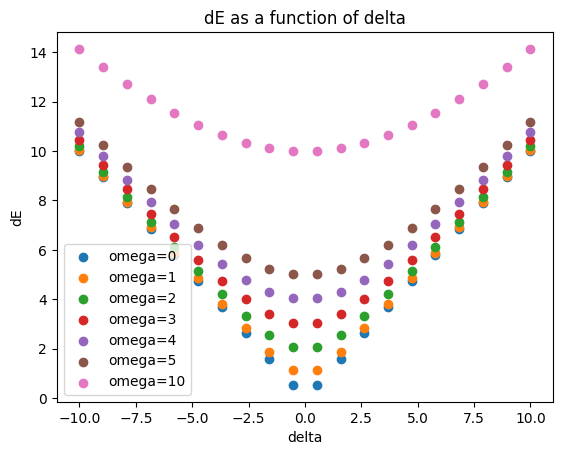

In [7]:
delta=np.linspace(-10, 10, 20)
omega=np.array([0,1, 2, 3, 4, 5,10])
for o in omega:
    plt.scatter(delta, dE_f(delta, o), label=f'omega={o}')
plt.xlabel('delta')
plt.ylabel('dE')
plt.title('dE as a function of delta')
plt.legend()
plt.show()

In [8]:
from qutip import sigmax, sigmay, sigmaz, qeye, basis, expect
from qutip import sesolve
from qutip import tensor, entropy_vn, concurrence
from qutip import Bloch

ModuleNotFoundError: No module named 'qutip'

In [ ]:
sx=sigmax()
sy=sigmay()
sz=sigmaz()

I make two pi pulses one with the x operator and one with the y operator.

X(pi/2)    -> (x,y,z) = [ 0. -0. -1.]
Y(pi/2)    -> (x,y,z) = [ 0. -0.  1.]
X(pi/2)    -> (x,y,z) = [ 0. -0.  1.]


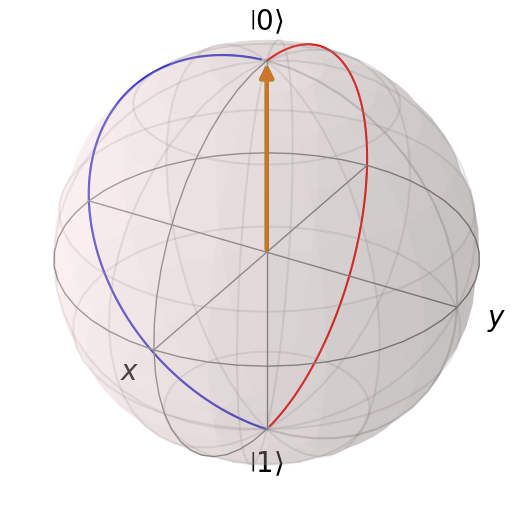

In [ ]:

N = 100          # delskridt per puls (kun for at tegne en glat bue)

def puls(psi, akse, vinkel, N=N):
    """Roter psi vinklen 'vinkel' om 'akse'. Returnerer (slut-psi, bane)."""
    dU = (-1j * (vinkel/N) / 2 * akse).expm()
    bane = []
    for _ in range(N):
        psi = dU * psi
        bane.append([expect(sx, psi), expect(sy, psi), expect(sz, psi)])
    return psi, np.array(bane).T          # bane = [xs, ys, zs]

# --- pulssekvens ------------------------------------------------
sekvens = [(sx, np.pi, "X(pi/2)"),
           (sy, np.pi, "Y(pi/2)"),
           (sx, 0*np.pi, "X(pi/2)")]

psi = basis(2, 0)                          # start i |0>
baner = []
for akse, vinkel, navn in sekvens:
    psi, bane = puls(psi, akse, vinkel)
    baner.append(bane)
    print(f"{navn:10s} -> (x,y,z) = {np.round(bane[:, -1], 3)}")

# --- plot -------------------------------------------------------
b = Bloch()
b.add_vectors([0, 0, 1])                   # starttilstand
for bane in baner:
    b.add_points(bane, meth='l')
b.add_vectors(list(baner[-1][:, -1]))      # sluttilstand
b.show()

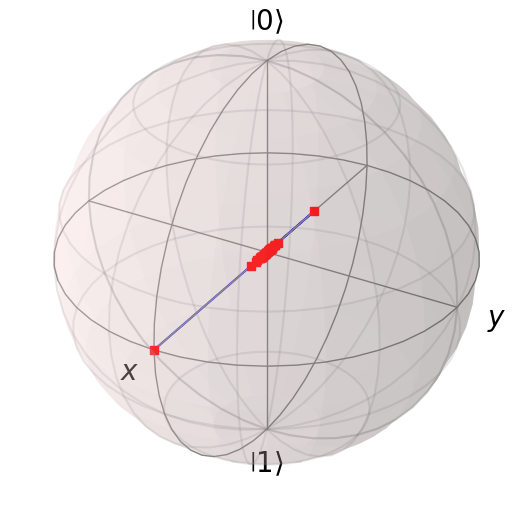

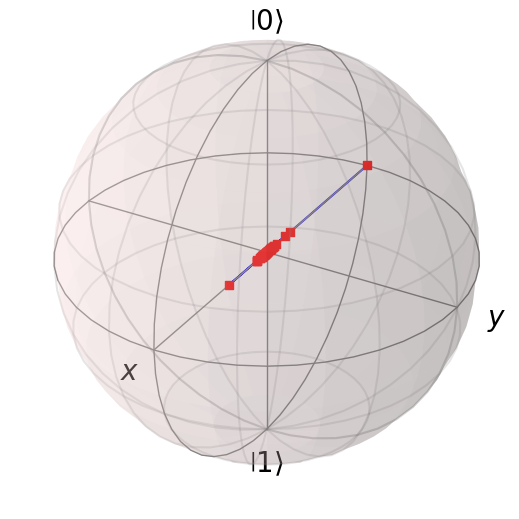

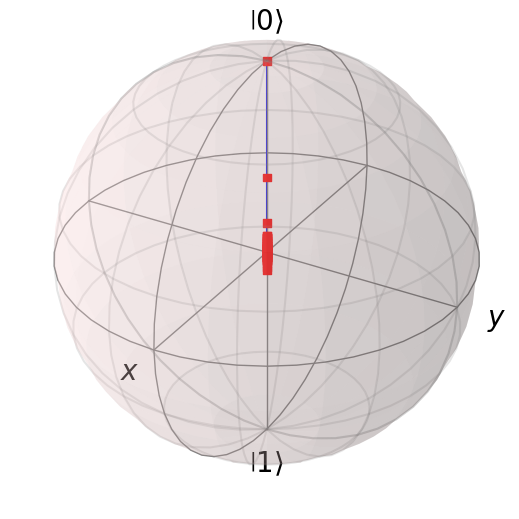

In [ ]:
def bloch_coords(psi):
    return [expect(sx, psi), expect(sy, psi), expect(sz, psi)]
def bit_flip(psi):
    return sx * psi

def phase_flip(psi):
    return sz * psi

rng = np.random.default_rng() 
def apply_noise(psi0, p, rng, n, M):
    coors = []
    for m in range(M):                     # M hele simuleringer
        psi = psi0                         # start forfra hver gang
        coor = [bloch_coords(psi)]
        for i in range(n):                 # n skridt
            if rng.random() < p:
                psi = bit_flip(psi)
            else:
                psi= phase_flip(psi)
            coor.append(bloch_coords(psi))
        coors.append(coor)
    return np.mean(coors, axis=0)          # form (n+1, 3)
psi0 = (basis(2, 0) + basis(2, 1)).unit()   # |+>: giver en mere interessant bane
psi1= (basis(2, 0) - basis(2, 1)).unit()   # |->: giver en mere interessant bane
psi3=basis(2, 0)                            # |0>
avg = apply_noise(psi3, 0.3, rng, n=20, M=500)
for psi in [psi0, psi1, psi3]:
    avg = apply_noise(psi, 0.3, rng, n=50, M=500)
    b = Bloch()
    b.add_points(avg.T, meth='l')
    b.add_points(avg.T)
    b.show()

In [ ]:
def noisy_sekvens(psi0, sekvens, p, rng, N=100):
    psi = psi0
    coor = [bloch_coords(psi)]
    for akse, vinkel, navn in sekvens:
        dU = (-1j * (vinkel/N) / 2 * akse).expm()
        for _ in range(N):
            psi = dU * psi                     # den normale rotation
            if rng.random() < p:               # sjælden fejl
                if rng.random() < 0.5:
                    psi, _ = bit_flip(psi)
                else:
                    psi, _ = phase_flip(psi)
            coor.append(bloch_coords(psi))
    return np.array(coor)

M, p = 300, 0.005
alle = np.array([noisy_sekvens(basis(2, 0), sekvens, p, rng) for _ in range(M)])
avg = np.mean(alle, axis=0)

b = Bloch()
b.add_points(noisy_sekvens(basis(2, 0), sekvens, 0, rng).T, meth='l')  # støjfri reference
b.add_points(avg.T, meth='l')                                          # gennemsnit med støj
b.show()

TypeError: Arguments must be quantum objects